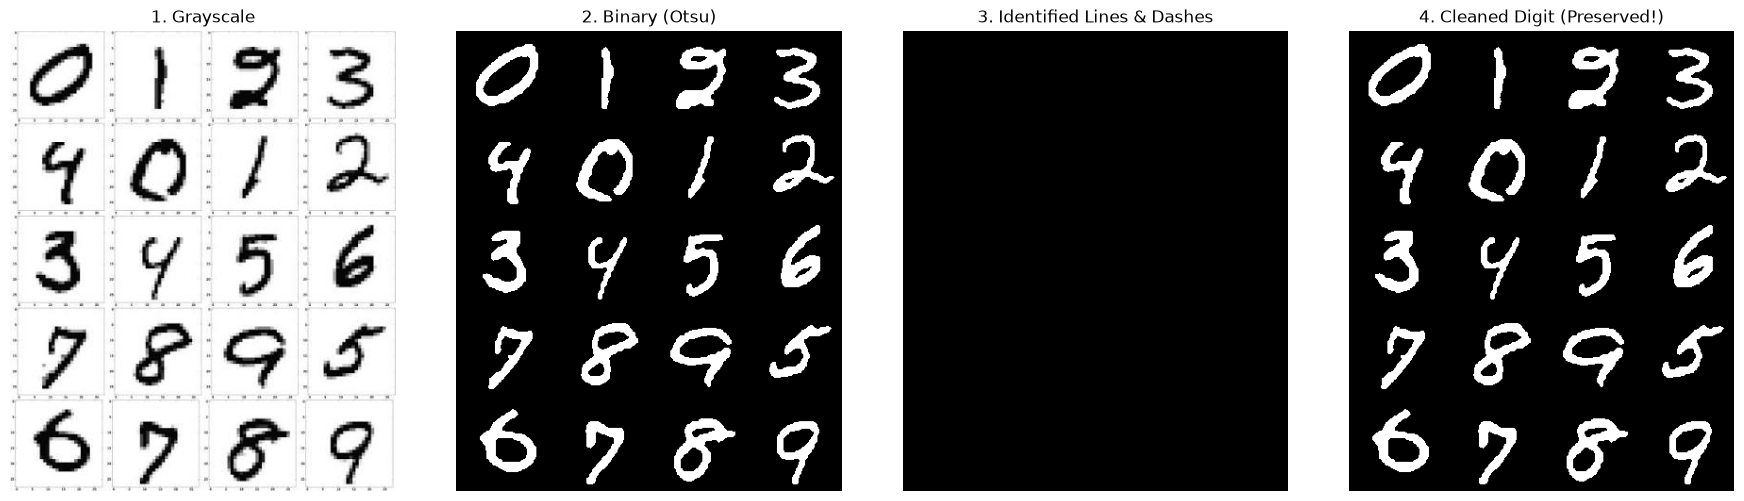

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract

img=cv.imread('photos/digit3.jpeg')

gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)

blur= cv.GaussianBlur(gray,(5,5),0)

#using otsus thresholding algorithm (binarization)
ret , thresh = cv.threshold(blur,0,255,cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

#componenet extraction
num_labels,labels,stats,centroid = cv.connectedComponentsWithStats(thresh)

#Create Two Blank Canvas of thresh size
detected_artifacts = np.zeros_like(thresh)
cleaned_digits=np.zeros_like(thresh)

image_width=img.shape[1]

for i in range(1,num_labels):
    x,y,w,h,area=stats[i]
    aspect_ratio=w/float(h)

    #propert-A is dashed or noise
    is_dashed_or_noise = (area<40 or h<10)

    #property-B is ruled_line
    is_ruled_line = (area>image_width*0.35 and aspect_ratio>5)

    if is_dashed_or_noise or is_ruled_line:
        detected_artifacts[labels==i]=255 #removal
    else:
        cleaned_digits[labels==i]=255 #keep

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(gray, cmap='gray')
axes[0].set_title('1. Grayscale')
axes[1].imshow(thresh, cmap='gray')
axes[1].set_title('2. Binary (Otsu)')
axes[2].imshow(detected_artifacts, cmap='gray')
axes[2].set_title('3. Identified Lines & Dashes')
axes[3].imshow(cleaned_digits, cmap='gray')
axes[3].set_title('4. Cleaned Digit (Preserved!)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

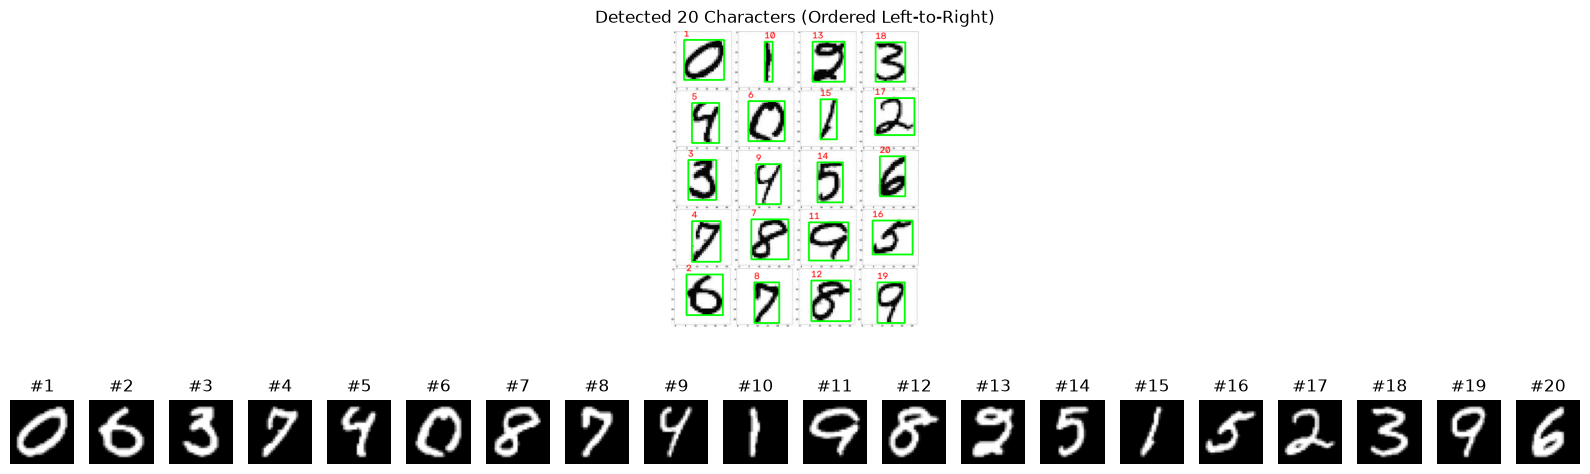

In [2]:
# ==========================================
# STAGE 2: SEGMENTATION & 28x28 NORMALIZATION
# ==========================================

# 1. Find all external contours from our cleaned binary image
contours, _ = cv.findContours(cleaned_digits, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

# print(contours[0])
# 2. Extract bounding boxes and filter any stray specks
raw_boxes = []
for c in contours:
    x, y, w, h = cv.boundingRect(c)
    # Filter out anything too tiny to be a digit or math symbol
    if w > 5 and h > 10:
        raw_boxes.append((x, y, w, h))

# 3. Sort bounding boxes from left to right (by x coordinate)
boxes = sorted(raw_boxes, key=lambda b: b[0])

# 4. Prepare visualization canvases
annotated_img = img.copy()
normalized_digits = []

for idx, (x, y, w, h) in enumerate(boxes):
    # A. Draw green bounding box & index label on the original image
    cv.rectangle(annotated_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv.putText(annotated_img, str(idx + 1), (x, y - 5),
               cv.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

    # B. Crop the digit from cleaned binary mask
    crop = cleaned_digits[y:y+h, x:x+w]

    # C. Center into a square canvas (preserves aspect ratio!)
    pad = 10
    max_dim = max(w, h) + 2 * pad
    square = np.zeros((max_dim, max_dim), dtype=np.uint8)

    # Calculate offsets to place crop in the exact center
    dx = (max_dim - w) // 2
    dy = (max_dim - h) // 2
    square[dy:dy+h, dx:dx+w] = crop

    # D. Resize to standard 28x28 (MNIST format)
    digit_28 = cv.resize(square, (28, 28), interpolation=cv.INTER_AREA)
    normalized_digits.append(digit_28)

# 5. Display the Results
fig = plt.figure(figsize=(16, 6))

# Panel 1: Bounding boxes detected on the input image
plt.subplot(2, 1, 1)
plt.imshow(cv.cvtColor(annotated_img, cv.COLOR_BGR2RGB))
plt.title(f'Detected {len(boxes)} Characters (Ordered Left-to-Right)')
plt.axis('off')

# Panel 2: The individual 28x28 normalized images ready for ML
for i, d in enumerate(normalized_digits):
    plt.subplot(2, len(normalized_digits), len(normalized_digits) + i + 1)
    plt.imshow(d, cmap='gray')
    plt.title(f'#{i+1}')
    plt.axis('off')

plt.tight_layout()
plt.show()

Loading MNIST training samples...
Training KNN (k=5)...
KNN Model Ready!


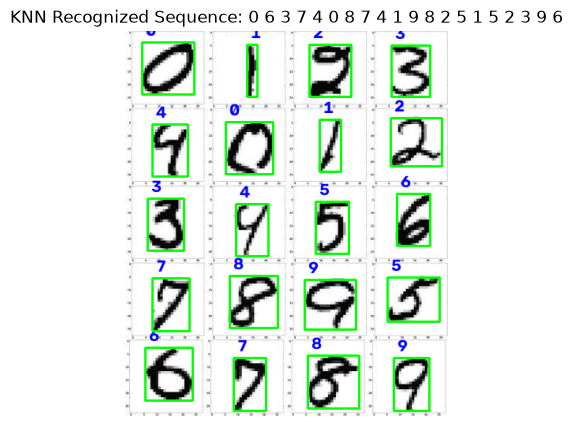

Final Extracted Sequence: 06374087419825152396


In [3]:
# ==========================================
# STAGE 3: DIGIT CLASSIFICATION WITH KNN (TUNED)
# ==========================================
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from torchvision import datasets
from scipy.ndimage import center_of_mass

# 1. Load MNIST Training Data
print("Loading MNIST training samples...")
mnist_train = datasets.MNIST('./data', train=True, download=False)
X_train = mnist_train.data.numpy()
y_train = mnist_train.targets.numpy()

# Flatten to (N, 784) and normalize
X_train_flat = X_train[:20000].reshape(-1, 28 * 28).astype(np.float32) / 255.0
y_train_subset = y_train[:20000]

# 2. Train KNN with k=5 (more robust against noisy outliers)
print("Training KNN (k=5)...")
knn = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
knn.fit(X_train_flat, y_train_subset)
print("KNN Model Ready!")

# 3. Helper: Stroke Thickening + Center-of-Mass Alignment
def align_to_mnist(crop):
    # Step A: Thicken ballpoint pen stroke to match MNIST marker thickness
    crop = cv.dilate(crop, np.ones((2, 2), np.uint8), iterations=1)
    
    h, w = crop.shape
    # Step B: Fit inside 20x20 box preserving aspect ratio
    if h > w:
        new_h = 20
        new_w = max(1, int(round(w * 20.0 / h)))
    else:
        new_w = 20
        new_h = max(1, int(round(h * 20.0 / w)))
        
    resized = cv.resize(crop, (new_w, new_h), interpolation=cv.INTER_AREA)
    
    # Step C: Place on 28x28 canvas
    canvas = np.zeros((28, 28), dtype=np.float32)
    start_y = (28 - new_h) // 2
    start_x = (28 - new_w) // 2
    canvas[start_y:start_y+new_h, start_x:start_x+new_w] = resized
    
    # Step D: Center by Center-of-Mass
    cy, cx = center_of_mass(canvas)
    if not (np.isnan(cy) or np.isnan(cx)):
        shift_y = int(round(14.0 - cy))
        shift_x = int(round(14.0 - cx))
        M = np.float32([[1, 0, shift_x], [0, 1, shift_y]])
        canvas = cv.warpAffine(canvas, M, (28, 28))
        
    return canvas.flatten() / 255.0

# 4. Predict
test_vectors = [align_to_mnist(cleaned_digits[y:y+h, x:x+w]) for x, y, w, h in boxes]
knn_predictions = knn.predict(np.array(test_vectors))

# 5. Visualize
result_img = img.copy()
for (x, y, w, h), pred in zip(boxes, knn_predictions):
    cv.rectangle(result_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv.putText(result_img, str(pred), (x + 5, y - 8),
               cv.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)

plt.figure(figsize=(14, 5))
plt.imshow(cv.cvtColor(result_img, cv.COLOR_BGR2RGB))
plt.title(f"KNN Recognized Sequence: {' '.join(str(p) for p in knn_predictions)}")
plt.axis('off')
plt.show()

print("Final Extracted Sequence:", "".join(str(p) for p in knn_predictions))

Loading MNIST test set...
Evaluating KNN model on 2,000 test samples...

✅ Overall Test Accuracy: 94.10%

Classification Report:
              precision    recall  f1-score   support

           0      0.956     1.000     0.978       175
           1      0.925     1.000     0.961       234
           2      0.985     0.909     0.945       219
           3      0.921     0.952     0.936       207
           4      0.948     0.931     0.940       217
           5      0.939     0.950     0.944       179
           6      0.961     0.972     0.966       178
           7      0.913     0.922     0.917       205
           8      0.970     0.844     0.903       192
           9      0.905     0.933     0.919       194

    accuracy                          0.941      2000
   macro avg      0.942     0.941     0.941      2000
weighted avg      0.942     0.941     0.941      2000



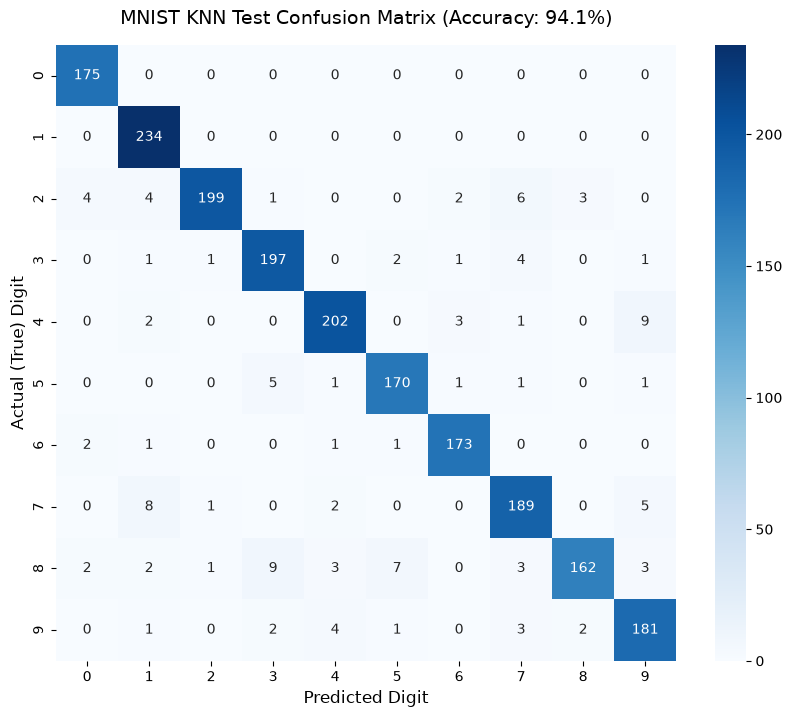


--- Current Image Prediction ---
Extracted Sequence: 0 6 3 7 4 0 8 7 4 1 9 8 2 5 1 5 2 3 9 6
ℹ️ Active image has 20 character(s) detected.


In [4]:
# ==========================================
# STAGE 3 EVALUATION: CONFUSION MATRIX & HEATMAP
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from torchvision import datasets

# 1. Load MNIST Test Dataset
print("Loading MNIST test set...")
mnist_test = datasets.MNIST('./data', train=False, download=False)
X_test = mnist_test.data.numpy()[:2000].reshape(-1, 28 * 28).astype(np.float32) / 255.0
y_test = mnist_test.targets.numpy()[:2000]

# 2. Run Predictions on Test SetIs there any more scope of improvement?
print("Evaluating KNN model on 2,000 test samples...")
y_test_pred = knn.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"\n✅ Overall Test Accuracy: {test_acc * 100:.2f}%\n")

# 3. Print Per-Digit Metrics (Precision, Recall, F1-Score)
print("Classification Report:")
print(classification_report(y_test, y_test_pred, digits=3))

# 4. Compute Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred, labels=list(range(10)))

# 5. Plot Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=[str(i) for i in range(10)],
            yticklabels=[str(i) for i in range(10)])

plt.title(f'MNIST KNN Test Confusion Matrix (Accuracy: {test_acc * 100:.1f}%)', fontsize=14, pad=15)
plt.xlabel('Predicted Digit', fontsize=12)
plt.ylabel('Actual (True) Digit', fontsize=12)
plt.show()

# 6. Accuracy on the Handwritten Image (Safe Check)
print("\n--- Current Image Prediction ---")
print(f"Extracted Sequence: {' '.join(str(p) for p in knn_predictions)}")

# If the active image is 'photos/digit.jpeg' (which has 9 digits 1..9):
if len(knn_predictions) == 9:
    y_photo_true = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9])
    photo_acc = accuracy_score(y_photo_true, knn_predictions)
    print(f"🎯 Accuracy on 'photos/digit.jpeg': {photo_acc * 100:.1f}%")
else:
    print(f"ℹ️ Active image has {len(knn_predictions)} character(s) detected.")